In [29]:
import numpy as np
import csv
import pandas as pd
from scipy.signal import find_peaks
#import seaborn as sns
import matplotlib.pyplot as plt
import scipy as sp
import os
from pathlib import Path
import glob
import joblib
import umap
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from numpy.linalg import norm
from sklearn.decomposition import PCA
from matplotlib.colors import LogNorm

In [2]:
SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output/UMAP/"))
if not os.path.exists(SAVEDIR):
    os.mkdir(SAVEDIR)

In [12]:
file_location = os.path.join('C:\\Users\\olesk\\ECM_mod_output\\dist_runs', 'stoch_sim*orig.csv')
filenames = glob.glob(file_location)
filenames = sorted(filenames)
# filenames_sp = [filenames[5], filenames[6], filenames[3], filenames[4], filenames[7], filenames[8]]
filenames_sp = [filenames[5], filenames[0], filenames[3], filenames[8],
                filenames[11], filenames[12], filenames[17], filenames[23]]
filenames_sp

['C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_dmso_stiff050_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_dmso_stiff000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_dmso_stiff030_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_dmso_stiff070_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_dmso_stiff099_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_erl_stiff000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_erl_stiff050_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_erl_stiff099_orig.csv']

In [13]:
file_location = os.path.join('C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\', 'ODE_sim*orig.csv')
filenames_ode = glob.glob(file_location)
filenames_ode = sorted(filenames_ode)
# filenames_sp_ode = [filenames_ode[2], filenames_ode[3], filenames_ode[0], filenames_ode[1], filenames_ode[4], filenames_ode[5]]
filenames_sp_ode = [filenames_ode[5], filenames_ode[0], filenames_ode[3], filenames_ode[8],
                    filenames_ode[11], filenames_ode[12], filenames_ode[17], filenames_ode[23]]
filenames_sp_ode

['C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_dmso_stiff050_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_dmso_stiff000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_dmso_stiff030_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_dmso_stiff070_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_dmso_stiff099_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_erl_stiff000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_erl_stiff050_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_erl_stiff099_orig.csv']

In [14]:
#The filenames to make the reducer umap object from
"""
filenames = ['erl_4-9_1_1.txt', 'erl_4-9_2_1.txt', 'erl_4-9_3_1.txt',
             'dmso_4-9_1_1.txt', 'dmso_4-9_2_1.txt', 'dmso_4-9_3_1.txt']
#Important params to set the window size and step time distance
init_dt = 0.01                #initial dt from the raw model output
dt = 0.1                      #dt for umap window
window = 4                    #window size in hours
time_step = 1                 #time step between windows

#umap params
neighbs = 100
min_d = 0.02
"""
# Important params to set the window size and step time distance
init_dt = 0.1                # initial dt from the raw model output
dt = 0.1                      # dt for umap window
window = 4                    # window size in hours
time_step = 0.5               # time step between windows

#umap params
neighbs = 50
min_d = 0.05

#reducer save name
r_name = f'reducer_07_25_{init_dt}_{dt}_{window}_{time_step}.sav'

In [15]:
def load_norm_data(filenames, filenames_ode, time_all, init_dt, dt, window, time_step, plot_phase):
    max_prots=[0]*18
    min_prots=[1000]*18
    
    for f in filenames:
        tmp_max=[]
        tmp_min=[]
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        #prot_tmp = prot_tmp/200
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this
        
        tmp_max = [prot_tmp[col].max() for col in prot_tmp]
        tmp_min = [prot_tmp[col].min() for col in prot_tmp]
        
        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]
        
    for f in filenames_ode:
        tmp_max=[]
        tmp_min=[]
        prot_tmp_ode = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this
        
        tmp_max = [prot_tmp_ode[col].max() for col in prot_tmp_ode]
        tmp_min = [prot_tmp_ode[col].min() for col in prot_tmp_ode]
        
        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]  
    
    if plot_phase:
        plot_phase(filenames_sp, filenames_sp_ode)
        plt.savefig(SAVE_DIR + f"phaseplot_{num}.png", bbox_inches='tight')
        plot_phase_norm(filenames_sp, filenames_sp_ode, max_prots, min_prots)
        plt.savefig(SAVE_DIR + f"phaseplot_norm_{num}.png", bbox_inches='tight')
    
    win_len = int(window/dt)
    all_prot_tmp = np.empty((0,win_len*18))     #careful, this could end up being massive 
    all_prot_tmp_ode = np.empty((0,win_len*18))
    all_time_tmp = np.empty((0,win_len))
    all_time_at_tmp = np.empty((0,1))
    range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))
        
    for (f, f_ode) in zip(filenames, filenames_ode):
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        #prot_tmp = prot_tmp/200
        for ii in range(18):
            prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))
        time_re_tmp = np.empty((len(range_ind),win_len))
        time_at_tmp = np.empty((len(range_ind),1))

        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)
            tmp_at = time_tmp2['time'].iloc[n]

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp = np.append(all_prot_tmp, prot_re_tmp, axis=0)
        all_time_tmp = np.append(all_time_tmp, time_re_tmp, axis=0)
        all_time_at_tmp = np.append(all_time_at_tmp, time_at_tmp, axis=0)
        
        prot_tmp_ode = pd.read_csv(f_ode, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        for ii in range(18):
            prot_tmp_ode.iloc[:,ii] = (prot_tmp_ode.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))


        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp_ode.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp_ode = np.append(all_prot_tmp_ode, prot_re_tmp, axis=0)
        
    return all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp
        

In [16]:
time_tmp = np.linspace(0, 20000, 200001)
time_tmp2 = pd.DataFrame(data=time_tmp)
time_tmp2.columns = ["time"]
plot_phase = False

In [17]:
[all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp] = load_norm_data(filenames_sp, filenames_sp_ode, time_tmp2, init_dt, dt, window, time_step, plot_phase)

In [18]:
reducer = joblib.load('C:\\Users\\olesk\\data\\reducer_07_25_0.1_0.1_4_0.5.sav')

In [19]:
win_len = int(window/dt)

In [20]:
embedding_all_prot = reducer.transform(all_prot_tmp)

In [19]:
# choose number of components and define pca
pca = PCA(n_components = 2)

# use the pca on the data (without the time column)
principalComponents = pca.fit_transform(all_prot_tmp)

In [21]:
win_len = int(window/dt)
all_prot_tmp_ode_ab = np.empty((0,win_len*18))
ab_len = 2000
w_len = len(all_prot_tmp_ode)/len(filenames_sp)
sp = 1
for n in range(len(filenames_sp)):
    tmp = all_prot_tmp_ode[int(sp*w_len-ab_len):int(sp*w_len),:]
    all_prot_tmp_ode_ab = np.append(all_prot_tmp_ode_ab, tmp, axis=0)
    sp += 1

In [22]:
embedding_all_prot_ode = reducer.transform(all_prot_tmp_ode_ab)

In [22]:
principalComponents = pca.fit_transform(all_prot_tmp)
principalComponents_ode = pca.transform(all_prot_tmp_ode_ab)

In [23]:
def restructProt(protDF, embedDF, timeDF):
    peaks_E, _ = find_peaks(protDF.iloc[:,int((win_len*11+win_len/2)-1)], prominence = 40/200, distance = 10)
    peaks_cdc, _ = find_peaks(protDF.iloc[:,int((win_len*17+win_len/2)-1)], prominence = 40/200, distance = 10)
    
    mit_win = pd.DataFrame()
    time_win = pd.DataFrame()
    umap_win = pd.DataFrame()
    num = 1
    
    for n in range(2,len(peaks_cdc)-3):   #make sure we have divisions at ends 
        tmp_mit = peaks_cdc[n]
        tmp_mit2 = peaks_cdc[n+1]
        tmp_mit3 = peaks_cdc[n+2]
        tmp_mit4 = peaks_cdc[n+3]
        
        tmp_g1_s = peaks_E[(tmp_mit < peaks_E) & (peaks_E < tmp_mit2)]
        tmp_g1_s_2 = peaks_E[(tmp_mit2 < peaks_E) & (peaks_E < tmp_mit3)]
        tmp_g1_s_3 = peaks_E[(tmp_mit3 < peaks_E) & (peaks_E < tmp_mit4)]    
             
        if (np.size(tmp_g1_s) > 0) & (np.size(tmp_g1_s_2)>0) & (np.size(tmp_g1_s_3)>0):
            ordered = [tmp_mit, tmp_g1_s[0], tmp_mit2, tmp_g1_s_2[0], tmp_mit3, tmp_g1_s_3[0], tmp_mit4]
            g1_len_tmp = np.array(timeDF.iloc[ordered[3],0]) - np.array(timeDF.iloc[[ordered[2]],0])
            tmp_prot = protDF.iloc[int(ordered[1]):int(ordered[4]),:]
            tmp_umap = embedDF.iloc[int(ordered[1]):int(ordered[4]),:]
            tmp_time = timeDF.iloc[int(ordered[1]):int(ordered[4]),:]
            tmp = [g1_len_tmp]*len(tmp_time)
            tmp_g1s = [int(ordered[1])]*len(tmp_time)
            tmp_mit = [int(ordered[2])]*len(tmp_time)
            tmp_g1s2 = [int(ordered[3])]*len(tmp_time)
            tmp_mit2 = [int(ordered[4])]*len(tmp_time)
            
            tmp_time.insert(0, 'mit2', tmp_mit2)
            tmp_time.insert(0, 'G1-S_2', tmp_g1s2)
            tmp_time.insert(0, 'mit', tmp_mit)
            tmp_time.insert(0, 'G1-S', tmp_g1s)
            tmp_time.insert(0, 'G1_len', tmp)
            tmp_time.insert(0, 'div', [num]*len(tmp_time))
            num += 1
            
            mit_win = pd.concat([mit_win,tmp_prot],ignore_index=True)
            time_win = pd.concat([time_win, tmp_time], ignore_index=True)
            umap_win = pd.concat([umap_win, tmp_umap], ignore_index=True)
            
    return mit_win, time_win, umap_win

In [24]:
from scipy.signal import find_peaks

In [25]:
trk_len = int(len(all_prot_tmp)/len(filenames_sp))
y_label_list = ['Skp2', 'p21', 'pp21', 'Cdh1', 'Myc', 'CycD', 'CycDp21', 'Rb', 'pRb', 'E2F', 'RbE2F',
                'CycE', 'CycEp21', 'CycA', 'CycAp21', 'CycB', 'CycBp21', 'Cdc20']
dmso_050_prot_df = pd.DataFrame(all_prot_tmp[0*trk_len:1*trk_len,:])
dmso_050_time_df = pd.DataFrame(all_time_tmp[0*trk_len:1*trk_len,:])
dmso_050_emb_df = pd.DataFrame(embedding_all_prot[0*trk_len:1*trk_len,:])

dmso_000_prot_df = pd.DataFrame(all_prot_tmp[1*trk_len:2*trk_len,:])
dmso_000_time_df = pd.DataFrame(all_time_tmp[1*trk_len:2*trk_len,:])
dmso_000_emb_df = pd.DataFrame(embedding_all_prot[1*trk_len:2*trk_len,:])

dmso_030_prot_df = pd.DataFrame(all_prot_tmp[2*trk_len:3*trk_len,:])
dmso_030_time_df = pd.DataFrame(all_time_tmp[2*trk_len:3*trk_len,:])
dmso_030_emb_df = pd.DataFrame(embedding_all_prot[2*trk_len:3*trk_len,:])

dmso_070_prot_df = pd.DataFrame(all_prot_tmp[3*trk_len:4*trk_len,:])
dmso_070_time_df = pd.DataFrame(all_time_tmp[3*trk_len:4*trk_len,:])
dmso_070_emb_df = pd.DataFrame(embedding_all_prot[3*trk_len:4*trk_len,:])

dmso_099_prot_df = pd.DataFrame(all_prot_tmp[4*trk_len:5*trk_len,:])
dmso_099_time_df = pd.DataFrame(all_time_tmp[4*trk_len:5*trk_len,:])
dmso_099_emb_df = pd.DataFrame(embedding_all_prot[4*trk_len:5*trk_len,:])

erl_000_prot_df = pd.DataFrame(all_prot_tmp[5*trk_len:6*trk_len,:])
erl_000_time_df = pd.DataFrame(all_time_tmp[5*trk_len:6*trk_len,:])
erl_000_emb_df = pd.DataFrame(embedding_all_prot[5*trk_len:6*trk_len,:])

erl_050_prot_df = pd.DataFrame(all_prot_tmp[6*trk_len:7*trk_len,:])
erl_050_time_df = pd.DataFrame(all_time_tmp[6*trk_len:7*trk_len,:])
erl_050_emb_df = pd.DataFrame(embedding_all_prot[6*trk_len:7*trk_len,:])

erl_099_prot_df = pd.DataFrame(all_prot_tmp[7*trk_len:8*trk_len,:])
erl_099_time_df = pd.DataFrame(all_time_tmp[7*trk_len:8*trk_len,:])
erl_099_emb_df = pd.DataFrame(embedding_all_prot[7*trk_len:8*trk_len,:])

In [24]:
trk_len = int(len(all_prot_tmp)/6)
y_label_list = ['Skp2', 'p21', 'pp21', 'Cdh1', 'Myc', 'CycD', 'CycDp21', 'Rb', 'pRb', 'E2F', 'RbE2F',
                'CycE', 'CycEp21', 'CycA', 'CycAp21', 'CycB', 'CycBp21', 'Cdc20']
erl_soft_prot_df = pd.DataFrame(all_prot_tmp[1*trk_len:2*trk_len,:])
erl_soft_time_df = pd.DataFrame(all_time_tmp[1*trk_len:2*trk_len,:])
erl_soft_emb_df = pd.DataFrame(embedding_all_prot[1*trk_len:2*trk_len,:])
erl_soft_pca_df = pd.DataFrame(principalComponents[1*trk_len:2*trk_len,:])

dmso_soft_prot_df = pd.DataFrame(all_prot_tmp[0*trk_len:1*trk_len,:])
dmso_soft_time_df = pd.DataFrame(all_time_tmp[0*trk_len:1*trk_len,:])
dmso_soft_emb_df = pd.DataFrame(embedding_all_prot[0*trk_len:1*trk_len,:])
dmso_soft_pca_df = pd.DataFrame(principalComponents[0*trk_len:1*trk_len,:])

In [25]:
trk_len = int(len(all_prot_tmp)/6)
y_label_list = ['Skp2', 'p21', 'pp21', 'Cdh1', 'Myc', 'CycD', 'CycDp21', 'Rb', 'pRb', 'E2F', 'RbE2F',
                'CycE', 'CycEp21', 'CycA', 'CycAp21', 'CycB', 'CycBp21', 'Cdc20']
erl_int_prot_df = pd.DataFrame(all_prot_tmp[3*trk_len:4*trk_len,:])
erl_int_time_df = pd.DataFrame(all_time_tmp[3*trk_len:4*trk_len,:])
erl_int_emb_df = pd.DataFrame(embedding_all_prot[3*trk_len:4*trk_len,:])
erl_int_pca_df = pd.DataFrame(principalComponents[3*trk_len:4*trk_len,:])

dmso_int_prot_df = pd.DataFrame(all_prot_tmp[2*trk_len:3*trk_len,:])
dmso_int_time_df = pd.DataFrame(all_time_tmp[2*trk_len:3*trk_len,:])
dmso_int_emb_df = pd.DataFrame(embedding_all_prot[2*trk_len:3*trk_len,:])
dmso_int_pca_df = pd.DataFrame(principalComponents[2*trk_len:3*trk_len,:])

In [26]:
trk_len = int(len(all_prot_tmp)/6)
y_label_list = ['Skp2', 'p21', 'pp21', 'Cdh1', 'Myc', 'CycD', 'CycDp21', 'Rb', 'pRb', 'E2F', 'RbE2F',
                'CycE', 'CycEp21', 'CycA', 'CycAp21', 'CycB', 'CycBp21', 'Cdc20']
erl_stiff_prot_df = pd.DataFrame(all_prot_tmp[5*trk_len:6*trk_len,:])
erl_stiff_time_df = pd.DataFrame(all_time_tmp[5*trk_len:6*trk_len,:])
erl_stiff_emb_df = pd.DataFrame(embedding_all_prot[5*trk_len:6*trk_len,:])
erl_stiff_pca_df = pd.DataFrame(principalComponents[5*trk_len:6*trk_len,:])

dmso_stiff_prot_df = pd.DataFrame(all_prot_tmp[4*trk_len:5*trk_len,:])
dmso_stiff_time_df = pd.DataFrame(all_time_tmp[4*trk_len:5*trk_len,:])
dmso_stiff_emb_df = pd.DataFrame(embedding_all_prot[4*trk_len:5*trk_len,:])
dmso_stiff_pca_df = pd.DataFrame(principalComponents[4*trk_len:5*trk_len,:])

In [27]:
mit_win_erl_soft, time_win_erl_soft, umap_win_erl_soft = restructProt(erl_soft_prot_df, erl_soft_emb_df, erl_soft_time_df)
mit_win_erl_soft, time_win_erl_soft, pca_win_erl_soft = restructProt(erl_soft_prot_df, erl_soft_pca_df, erl_soft_time_df)

mit_win_dmso_soft, time_win_dmso_soft, umap_win_dmso_soft = restructProt(dmso_soft_prot_df, dmso_soft_emb_df, dmso_soft_time_df)
mit_win_dmso_soft, time_win_dmso_soft, pca_win_dmso_soft = restructProt(dmso_soft_prot_df, dmso_soft_pca_df, dmso_soft_time_df)

mit_win_erl_int, time_win_erl_int, umap_win_erl_int = restructProt(erl_int_prot_df, erl_int_emb_df, erl_int_time_df)
mit_win_erl_int, time_win_erl_int, pca_win_erl_int = restructProt(erl_int_prot_df, erl_int_pca_df, erl_int_time_df)

mit_win_dmso_int, time_win_dmso_int, umap_win_dmso_int = restructProt(dmso_int_prot_df, dmso_int_emb_df, dmso_int_time_df)
mit_win_dmso_int, time_win_dmso_int, pca_win_dmso_int = restructProt(dmso_int_prot_df, dmso_int_pca_df, dmso_int_time_df)



In [118]:
mit_win_erl_stiff, time_win_erl_stiff, umap_win_erl_stiff = restructProt(erl_stiff_prot_df, erl_stiff_emb_df, erl_stiff_time_df)
mit_win_erl_stiff, time_win_erl_stiff, pca_win_erl_stiff = restructProt(erl_stiff_prot_df, erl_stiff_pca_df, erl_stiff_time_df)

mit_win_dmso_stiff, time_win_dmso_stiff, umap_win_dmso_stiff = restructProt(dmso_stiff_prot_df, dmso_stiff_emb_df, dmso_stiff_time_df)
mit_win_dmso_stiff, time_win_dmso_stiff, pca_win_dmso_stiff = restructProt(dmso_stiff_prot_df, dmso_stiff_pca_df, dmso_stiff_time_df)


In [26]:
mit_win_dmso_050, time_win_dmso_050, umap_win_dmso_050 = restructProt(dmso_050_prot_df, dmso_050_emb_df, dmso_050_time_df)
mit_win_dmso_000, time_win_dmso_000, umap_win_dmso_000 = restructProt(dmso_000_prot_df, dmso_000_emb_df, dmso_000_time_df)
mit_win_dmso_030, time_win_dmso_030, umap_win_dmso_030 = restructProt(dmso_030_prot_df, dmso_030_emb_df, dmso_030_time_df)
mit_win_dmso_070, time_win_dmso_070, umap_win_dmso_070 = restructProt(dmso_070_prot_df, dmso_070_emb_df, dmso_070_time_df)
mit_win_dmso_099, time_win_dmso_099, umap_win_dmso_099 = restructProt(dmso_099_prot_df, dmso_099_emb_df, dmso_099_time_df)
mit_win_erl_000, time_win_erl_000, umap_win_erl_000 = restructProt(erl_000_prot_df, erl_000_emb_df, erl_000_time_df)
mit_win_erl_050, time_win_erl_050, umap_win_erl_050 = restructProt(erl_050_prot_df, erl_050_emb_df, erl_050_time_df)
mit_win_erl_099, time_win_erl_099, umap_win_erl_099 = restructProt(erl_099_prot_df, erl_099_emb_df, erl_099_time_df)

In [27]:
size = (4,4)
xmin = -10
xmax = 20
ymin = 0
ymax = 20
wid = 1
trk_len_ode = int(len(embedding_all_prot_ode)/len(filenames_sp))

C:\Users\olesk\AppData\Local\Temp\ipykernel_31288\2997415852.py:19: DeprecationWarning: Please use `gaussian_filter` from the `scipy.ndimage` namespace, the `scipy.ndimage.filters` namespace is deprecated.
  H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')


[None, None, None, None]

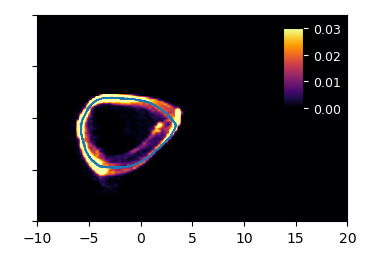

In [43]:
fig = plt.figure(figsize=size)

# params = {'axes.titley': 1,
#          'axes.titlepad': -14,
#          'axes.labelsize': 14,
#          'axes.titlesize': 14,
#          'xtick.labelsize': 12,
#          'ytick.labelsize': 12}
# plt.rcParams.update(params)

xmin, xmax = -10, 20
ymin, ymax = 0, 20

x = np.array(umap_win_erl_099[0])
y = np.array(umap_win_erl_099[1])
H, xedges, yedges = np.histogram2d(x, y, bins=100, range= [[xmin,xmax], [ymin,ymax]], density=True)
# Apply gaussian filter
sigma = [3, 3]
H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')
#H2[H2>0.01] = 0


#fig = plt.figure()
ax = fig.gca()
#ax.set_xlim(xmin, xmax)
#ax.set_ylim(ymin, ymax)
#fig.set_size_inches(5, 5)
tmp = embedding_all_prot_ode[7*trk_len_ode:8*trk_len_ode,:]
im = plt.imshow((np.rot90(H)), extent=[xmin, xmax, ymin, ymax], 
                interpolation='bilinear', cmap='inferno')
im.set_clim(0, 0.03)
plt.plot(tmp[500:,0], tmp[500:,1],
         lw=0.5, alpha=1, label='DMSO_50')
# tmp = embedding_all_prot_ode[2*trk_len_ode:3*trk_len_ode,:]
# plt.plot(tmp[500:,0], tmp[500:,1],
#          lw=0.5, alpha=1, label='DMSO_30')
# tmp = embedding_all_prot_ode[3*trk_len_ode:4*trk_len_ode,:]
# plt.plot(tmp[500:,0], tmp[500:,1],
#          lw=0.5, alpha=1, label='DMSO_70')
# plt.legend(loc="upper right")

plt.xlim(-10,20)
plt.ylim(0, 20)

# plt.xticks(color='w')
plt.yticks(color='w')

cbar_ax = fig.add_axes([0.74, 0.52, 0.05, 0.2])
cb = fig.colorbar(im, cax=cbar_ax)
cb.ax.tick_params(labelsize=9)
cb.ax.yaxis.set_tick_params(color='white')
plt.setp(plt.getp(cb.ax.axes, 'yticklabels'), color='white')



C:\Users\olesk\AppData\Local\Temp\ipykernel_20436\1213034444.py:19: DeprecationWarning: Please use `gaussian_filter` from the `scipy.ndimage` namespace, the `scipy.ndimage.filters` namespace is deprecated.
  H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')


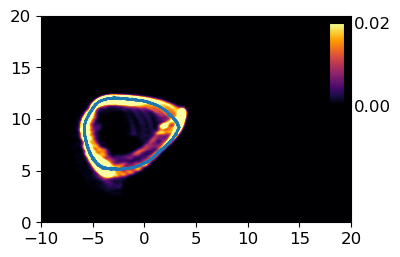

In [119]:
fig = plt.figure(figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

xmin, xmax = -10, 20
ymin, ymax = 0, 20

x = np.array(umap_win_erl_stiff[0])
y = np.array(umap_win_erl_stiff[1])
H, xedges, yedges = np.histogram2d(x, y, bins=500, range= [[xmin,xmax], [ymin,ymax]], density=True)
# Apply gaussian filter
sigma = [3, 3]
H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')
#H2[H2>0.01] = 0


#fig = plt.figure()
ax = fig.gca()
#ax.set_xlim(xmin, xmax)
#ax.set_ylim(ymin, ymax)
#fig.set_size_inches(5, 5)
tmp = embedding_all_prot_ode[5*trk_len_ode:6*trk_len_ode,:]
im = plt.imshow((np.rot90(H2)), extent=[xmin, xmax, ymin, ymax], cmap='inferno')
im.set_clim(0, 0.02)
plt.plot(tmp[500:,0], tmp[500:,1],
         lw=1, alpha=1)
axins1 = inset_axes(
    ax,
    width="5%",  # width: 50% of parent_bbox width
    height="40%",  # height: 5%
    loc="upper right",
)

cbar = fig.colorbar(im, cax=axins1, ticks=[0, 0.02])



C:\Users\olesk\AppData\Local\Temp\ipykernel_20436\1934004755.py:19: DeprecationWarning: Please use `gaussian_filter` from the `scipy.ndimage` namespace, the `scipy.ndimage.filters` namespace is deprecated.
  H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')


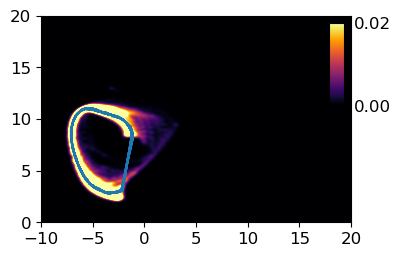

In [120]:
fig = plt.figure(figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

xmin, xmax = -10, 20
ymin, ymax = 0, 20

x = np.array(umap_win_dmso_stiff[0])
y = np.array(umap_win_dmso_stiff[1])
H, xedges, yedges = np.histogram2d(x, y, bins=500, range= [[xmin,xmax], [ymin,ymax]], density=True)
# Apply gaussian filter
sigma = [3, 3]
H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')
#H2[H2>0.01] = 0


#fig = plt.figure()
ax = fig.gca()
#ax.set_xlim(xmin, xmax)
#ax.set_ylim(ymin, ymax)
#fig.set_size_inches(5, 5)
tmp = embedding_all_prot_ode[4*trk_len_ode:5*trk_len_ode,:]
im = plt.imshow((np.rot90(H2)), extent=[xmin, xmax, ymin, ymax], cmap='inferno')
im.set_clim(0, 0.02)
plt.plot(tmp[500:,0], tmp[500:,1],
         lw=1, alpha=1)
axins1 = inset_axes(
    ax,
    width="5%",  # width: 50% of parent_bbox width
    height="40%",  # height: 5%
    loc="upper right",
)

cbar = fig.colorbar(im, cax=axins1, ticks=[0, 0.02])



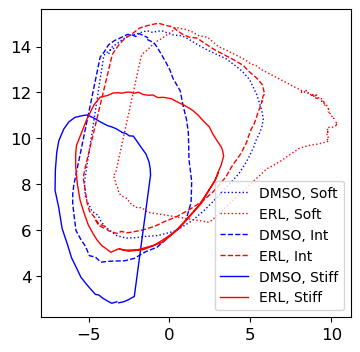

In [160]:
fig = plt.figure(figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

xmin, xmax = -10, 20
ymin, ymax = 0, 20

#fig = plt.figure()
ax = fig.gca()

plt.plot(embedding_all_prot_ode[0*trk_len_ode:0*trk_len_ode+55,0], 
         embedding_all_prot_ode[0*trk_len_ode:0*trk_len_ode+55,1],
         lw=1, alpha=1, linestyle=':', label='DMSO, Soft', color='blue')
plt.plot(embedding_all_prot_ode[1*trk_len_ode:1*trk_len_ode+135,0], 
         embedding_all_prot_ode[1*trk_len_ode:1*trk_len_ode+135,1],
         lw=1, alpha=1, linestyle=':', label='ERL, Soft', color='red')

plt.plot(embedding_all_prot_ode[2*trk_len_ode:2*trk_len_ode+45,0], 
         embedding_all_prot_ode[2*trk_len_ode:2*trk_len_ode+45,1],
         lw=1, alpha=1, linestyle='--', label='DMSO, Int', color='blue')
plt.plot(embedding_all_prot_ode[3*trk_len_ode:3*trk_len_ode+65,0], 
         embedding_all_prot_ode[3*trk_len_ode:3*trk_len_ode+65,1],
         lw=1, alpha=1, linestyle='--', label='ERL, Int', color='red')

plt.plot(embedding_all_prot_ode[4*trk_len_ode:4*trk_len_ode+45,0], 
         embedding_all_prot_ode[4*trk_len_ode:4*trk_len_ode+45,1],
         lw=1, alpha=1, linestyle='-', label='DMSO, Stiff', color='blue')
plt.plot(embedding_all_prot_ode[5*trk_len_ode:5*trk_len_ode+65,0], 
         embedding_all_prot_ode[5*trk_len_ode:5*trk_len_ode+65,1],
         lw=1, alpha=1, linestyle='-', label='ERL, Stiff', color='red')

plt.legend()

C:\Users\olesk\AppData\Local\Temp\ipykernel_20436\1204342043.py:20: DeprecationWarning: Please use `gaussian_filter` from the `scipy.ndimage` namespace, the `scipy.ndimage.filters` namespace is deprecated.
  H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')


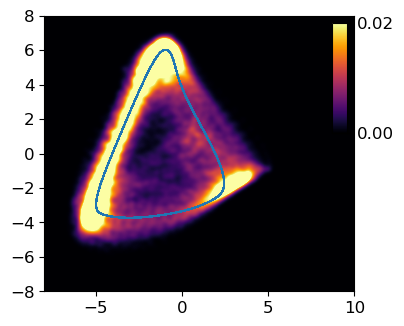

In [129]:
fig = plt.figure(figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

xmin, xmax = -8, 10
ymin, ymax = -8, 8

x = np.array(pca_win_erl_stiff[0])
y = np.array(pca_win_erl_stiff[1])
H, xedges, yedges = np.histogram2d(x, y, bins=350, range= [[xmin,xmax], [ymin,ymax]], density=True)
#H = H+0.00001
# Apply gaussian filter
sigma = [3, 3]
H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')
#H2[H2>0.01] = 0


#fig = plt.figure()
ax = fig.gca()
#ax.set_xlim(xmin, xmax)
#ax.set_ylim(ymin, ymax)
#fig.set_size_inches(5, 5)
tmp = principalComponents_ode[5*trk_len_ode:6*trk_len_ode,:]
im = plt.imshow((np.rot90(H2)), extent=[xmin, xmax, ymin, ymax], cmap='inferno')
#im = plt.imshow((np.rot90(H2)), extent=[xmin, xmax, ymin, ymax], norm=LogNorm(), cmap='inferno')
im.set_clim(0, 0.02)
plt.plot(tmp[500:,0], tmp[500:,1],
         lw=1, alpha=1)
axins1 = inset_axes(
    ax,
    width="5%",  # width: 50% of parent_bbox width
    height="40%",  # height: 5%
    loc="upper right",
)

cbar = fig.colorbar(im, cax=axins1, ticks=[0, 0.02])



C:\Users\olesk\AppData\Local\Temp\ipykernel_20436\3797477722.py:20: DeprecationWarning: Please use `gaussian_filter` from the `scipy.ndimage` namespace, the `scipy.ndimage.filters` namespace is deprecated.
  H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')


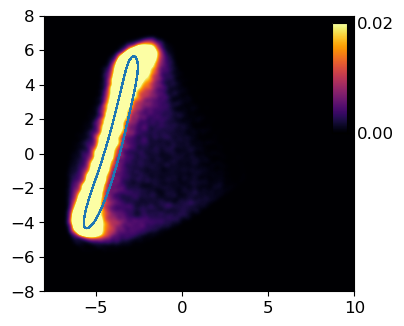

In [130]:
fig = plt.figure(figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

xmin, xmax = -8, 10
ymin, ymax = -8, 8

x = np.array(pca_win_dmso_stiff[0])
y = np.array(pca_win_dmso_stiff[1])
H, xedges, yedges = np.histogram2d(x, y, bins=350, range= [[xmin,xmax], [ymin,ymax]], density=True)
#H = H+0.00001
# Apply gaussian filter
sigma = [3, 3]
H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')
#H2[H2>0.01] = 0


#fig = plt.figure()
ax = fig.gca()
#ax.set_xlim(xmin, xmax)
#ax.set_ylim(ymin, ymax)
#fig.set_size_inches(5, 5)
tmp = principalComponents_ode[4*trk_len_ode:5*trk_len_ode,:]
im = plt.imshow((np.rot90(H2)), extent=[xmin, xmax, ymin, ymax], cmap='inferno')
#im = plt.imshow((np.rot90(H2)), extent=[xmin, xmax, ymin, ymax], norm=LogNorm(), cmap='inferno')
im.set_clim(0, 0.02)
plt.plot(tmp[500:,0], tmp[500:,1],
         lw=1, alpha=1)
axins1 = inset_axes(
    ax,
    width="5%",  # width: 50% of parent_bbox width
    height="40%",  # height: 5%
    loc="upper right",
)

cbar = fig.colorbar(im, cax=axins1, ticks=[0, 0.02])



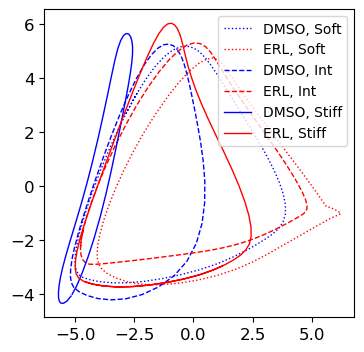

In [161]:
fig = plt.figure(figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

xmin, xmax = -8, 10
ymin, ymax = -8, 8

#fig = plt.figure()
ax = fig.gca()

plt.plot(principalComponents_ode[0*trk_len_ode:0*trk_len_ode+55,0], 
         principalComponents_ode[0*trk_len_ode:0*trk_len_ode+55,1],
         lw=1, alpha=1, linestyle=':', label='DMSO, Soft', color='blue')
plt.plot(principalComponents_ode[1*trk_len_ode:1*trk_len_ode+135,0], 
         principalComponents_ode[1*trk_len_ode:1*trk_len_ode+135,1],
         lw=1, alpha=1, linestyle=':', label='ERL, Soft', color='red')

plt.plot(principalComponents_ode[2*trk_len_ode:2*trk_len_ode+45,0], 
         principalComponents_ode[2*trk_len_ode:2*trk_len_ode+45,1],
         lw=1, alpha=1, linestyle='--', label='DMSO, Int', color='blue')
plt.plot(principalComponents_ode[3*trk_len_ode:3*trk_len_ode+65,0], 
         principalComponents_ode[3*trk_len_ode:3*trk_len_ode+65,1],
         lw=1, alpha=1, linestyle='--', label='ERL, Int', color='red')

plt.plot(principalComponents_ode[4*trk_len_ode:4*trk_len_ode+45,0], 
         principalComponents_ode[4*trk_len_ode:4*trk_len_ode+45,1],
         lw=1, alpha=1, linestyle='-', label='DMSO, Stiff', color='blue')
plt.plot(principalComponents_ode[5*trk_len_ode:5*trk_len_ode+65,0], 
         principalComponents_ode[5*trk_len_ode:5*trk_len_ode+65,1],
         lw=1, alpha=1, linestyle='-', label='ERL, Stiff', color='red')

plt.legend()

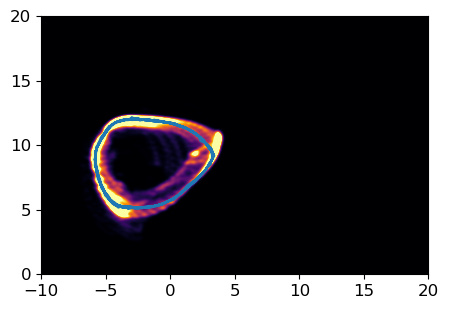

In [165]:
fig = plt.figure(figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

xmin, xmax = -10, 20
ymin, ymax = 0, 20

x = np.array(umap_win_erl_stiff[0])
y = np.array(umap_win_erl_stiff[1])
H, xedges, yedges = np.histogram2d(x, y, bins=1000, range= [[xmin,xmax], [ymin,ymax]], density=True)
# Apply gaussian filter
sigma = [5, 5]
H2 = sp.ndimage.gaussian_filter(H, sigma, mode='constant')
#H2[H2>0.01] = 0


# fig = plt.figure()
# ax = fig.gca()
#ax.set_xlim(xmin, xmax)
#ax.set_ylim(ymin, ymax)
fig.set_size_inches(5, 5)
im = plt.imshow((np.rot90(H2)), extent=[xmin, xmax, ymin, ymax], cmap='inferno')
im.set_clim(0, 0.03)
tmp = embedding_all_prot_ode[5*trk_len_ode:6*trk_len_ode,:]
plt.plot(tmp[500:,0], tmp[500:,1],
         lw=1, alpha=1)





In [32]:
##CycDi

In [78]:
file_location = os.path.join('C:\\Users\\olesk\\ECM_mod_output\\', 'stoch_sim*cycdi.csv')
filenames = glob.glob(file_location)
filenames = sorted(filenames)
filenames_sp = [filenames[2], filenames[3], filenames[0], filenames[1], filenames[4], filenames[5]]
filenames_sp
file_location = os.path.join('C:\\Users\\olesk\\ECM_mod_output\\', 'ODE_sim*cycdi.csv')
filenames_ode = glob.glob(file_location)
filenames_ode = sorted(filenames_ode)
filenames_sp_ode = [filenames_ode[2], filenames_ode[3], filenames_ode[0], filenames_ode[1], filenames_ode[4], filenames_ode[5]]
filenames_sp_ode

['C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_soft_DMSO_param_cycdi.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_soft_erl_param_cycdi.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_int_DMSO_param_cycdi.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_int_erl_param_cycdi.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_stiff_DMSO_param_cycdi.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_stiff_erl_param_cycdi.csv']

In [79]:
[all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp] = load_norm_data(filenames_sp, filenames_sp_ode, time_tmp2, init_dt, dt, window, time_step, plot_phase)

In [80]:
embedding_all_prot = reducer.transform(all_prot_tmp)

In [81]:
trk_len = int(len(all_prot_tmp)/6)
y_label_list = ['Skp2', 'p21', 'pp21', 'Cdh1', 'Myc', 'CycD', 'CycDp21', 'Rb', 'pRb', 'E2F', 'RbE2F',
                'CycE', 'CycEp21', 'CycA', 'CycAp21', 'CycB', 'CycBp21', 'Cdc20']
erl_int_prot_df = pd.DataFrame(all_prot_tmp[3*trk_len:4*trk_len,:])
erl_int_time_df = pd.DataFrame(all_time_tmp[3*trk_len:4*trk_len,:])
erl_int_emb_df = pd.DataFrame(embedding_all_prot[3*trk_len:4*trk_len,:])

In [82]:
mit_win_erl_int, time_win_erl_int, umap_win_erl_int = restructProt(erl_int_prot_df, erl_int_emb_df, erl_int_time_df)

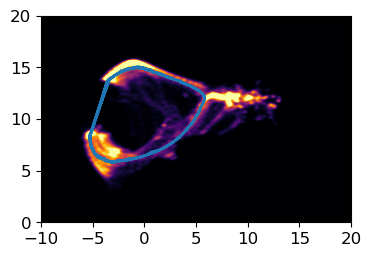

In [164]:
fig = plt.figure(figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

xmin, xmax = -10, 20
ymin, ymax = 0, 20

x = np.array(umap_win_erl_int[0])
y = np.array(umap_win_erl_int[1])
H, xedges, yedges = np.histogram2d(x, y, bins=1000, range= [[xmin,xmax], [ymin,ymax]], density=True)
# Apply gaussian filter
sigma = [5, 5]
H2 = sp.ndimage.gaussian_filter(H, sigma, mode='constant')
#H2[H2>0.01] = 0


# fig = plt.figure()
# ax = fig.gca()
#ax.set_xlim(xmin, xmax)
#ax.set_ylim(ymin, ymax)
# fig.set_size_inches(5, 5)
im = plt.imshow((np.rot90(H2)), extent=[xmin, xmax, ymin, ymax], cmap='inferno')
im.set_clim(0, 0.03)
tmp = embedding_all_prot_ode[3*trk_len_ode:4*trk_len_ode,:]
plt.plot(tmp[500:,0], tmp[500:,1],
         lw=1, alpha=1)





In [ ]:
#CycBi

In [53]:
file_location = os.path.join('C:\\Users\\olesk\\ECM_mod_output\\', 'stoch_sim*cycbi.csv')
filenames = glob.glob(file_location)
filenames = sorted(filenames)
filenames_sp = [filenames[2], filenames[3], filenames[0], filenames[1], filenames[4], filenames[5]]
filenames_sp
file_location = os.path.join('C:\\Users\\olesk\\ECM_mod_output\\', 'ODE_sim*cycbi.csv')
filenames_ode = glob.glob(file_location)
filenames_ode = sorted(filenames_ode)
filenames_sp_ode = [filenames_ode[2], filenames_ode[3], filenames_ode[0], filenames_ode[1], filenames_ode[4], filenames_ode[5]]
filenames_sp_ode

['C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_soft_DMSO_param_cycbi.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_soft_erl_param_cycbi.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_int_DMSO_param_cycbi.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_int_erl_param_cycbi.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_stiff_DMSO_param_cycbi.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_stiff_erl_param_cycbi.csv']

In [54]:
[all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp] = load_norm_data(filenames_sp, filenames_sp_ode, time_tmp2, init_dt, dt, window, time_step, plot_phase)

In [55]:
embedding_all_prot = reducer.transform(all_prot_tmp)

In [56]:
trk_len = int(len(all_prot_tmp)/6)
y_label_list = ['Skp2', 'p21', 'pp21', 'Cdh1', 'Myc', 'CycD', 'CycDp21', 'Rb', 'pRb', 'E2F', 'RbE2F',
                'CycE', 'CycEp21', 'CycA', 'CycAp21', 'CycB', 'CycBp21', 'Cdc20']
erl_int_prot_df = pd.DataFrame(all_prot_tmp[3*trk_len:4*trk_len,:])
erl_int_time_df = pd.DataFrame(all_time_tmp[3*trk_len:4*trk_len,:])
erl_int_emb_df = pd.DataFrame(embedding_all_prot[3*trk_len:4*trk_len,:])

In [57]:
mit_win_erl_int, time_win_erl_int, umap_win_erl_int = restructProt(erl_int_prot_df, erl_int_emb_df, erl_int_time_df)

C:\Users\olesk\AppData\Local\Temp\ipykernel_16440\2289919992.py:19: DeprecationWarning: Please use `gaussian_filter` from the `scipy.ndimage` namespace, the `scipy.ndimage.filters` namespace is deprecated.
  H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')


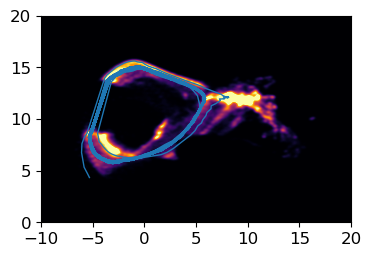

In [58]:
fig = plt.figure(figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

xmin, xmax = -10, 20
ymin, ymax = 0, 20

x = np.array(umap_win_erl_int[0])
y = np.array(umap_win_erl_int[1])
H, xedges, yedges = np.histogram2d(x, y, bins=1000, range= [[xmin,xmax], [ymin,ymax]], density=True)
# Apply gaussian filter
sigma = [5, 5]
H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')
#H2[H2>0.01] = 0


# fig = plt.figure()
# ax = fig.gca()
#ax.set_xlim(xmin, xmax)
#ax.set_ylim(ymin, ymax)
# fig.set_size_inches(5, 5)
im = plt.imshow((np.rot90(H2)), extent=[xmin, xmax, ymin, ymax], cmap='inferno')
im.set_clim(0, 0.03)
plt.plot(embedding_all_prot_ode[3*trk_len_ode:4*trk_len_ode,0], embedding_all_prot_ode[3*trk_len_ode:4*trk_len_ode,1],
         lw=1, alpha=1)



